# AI-Powered Network Intrusion Detection System

## Notebook 03 – Feature Engineering & Feature Selection

**Author:** Jithesh  
**Role:** Member A – ML & Data Engineer  
**Dataset:** CICIDS-2017  
**Date:** 18 August 2026

---

## Objective

This notebook performs feature engineering and feature selection on the cleaned CICIDS-2017 dataset prepared in Notebook 02.

### Tasks

- Load the persisted cleaned CICIDS-2017 dataset
- Validate the recovered dataset and its structure
- Analyze the available features and their data types
- Identify redundant and highly correlated features
- Investigate low-variance and non-informative features
- Apply appropriate feature transformation and selection techniques
- Prepare a final feature set for model development
- Persist the resulting feature-engineered dataset for subsequent modeling

## Environment Setup

This section initializes the working environment by mounting Google Drive, importing the required libraries, defining the project paths, and loading the persisted dataset generated during Notebook 02.

The persisted dataset is used so that feature engineering can be resumed after a Colab runtime disconnection without rerunning the complete data-cleaning pipeline.

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Import Libraries

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Define Project Paths

The project follows the directory structure established during the previous preprocessing stage. The processed dataset generated by Notebook 02 will be loaded from the project storage area rather than reconstructing it from the raw CICIDS-2017 files.

In [5]:
PROJECT_PATH = "/content/drive/MyDrive/AI-Network-Intrusion-Detection-System"

DATA_PATH = os.path.join(PROJECT_PATH, "data")
RAW_DATA_PATH = os.path.join(DATA_PATH, "raw")
PROCESSED_DATA_PATH = os.path.join(DATA_PATH, "processed")

print("Project Path:", PROJECT_PATH)
print("Processed Data Path:", PROCESSED_DATA_PATH)

Project Path: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System
Processed Data Path: /content/drive/MyDrive/AI-Network-Intrusion-Detection-System/data/processed


### Verify Processed Dataset Directory

The processed-data directory is checked before loading the dataset. This ensures that the persisted output from Notebook 02 is available and prevents the notebook from silently proceeding with an incorrect or missing input file.

In [6]:
os.listdir(PROCESSED_DATA_PATH)

['CICIDS2017_cleaned.parquet', 'CICIDS2017_stage1_feature_engineered.parquet']

### Load Persisted Cleaned Dataset

The cleaned CICIDS-2017 dataset generated during Notebook 02 is loaded from the processed-data directory.

Using the persisted dataset allows this notebook to continue directly with feature engineering without repeating the complete data-cleaning pipeline.

In [7]:
CLEANED_DATA_PATH = os.path.join(
    PROCESSED_DATA_PATH,
    "CICIDS2017_cleaned.parquet"
)

df = pd.read_parquet(CLEANED_DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (2830743, 67)


### Verify Recovered Dataset

Before beginning feature engineering, the recovered dataset is inspected to confirm that the data has been loaded correctly and that the expected records and features are available.

In [8]:
print("Number of records:", len(df))
print("Number of features:", df.shape[1])

df.head()

Number of records: 2830743
Number of features: 67


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Target
0,80,38308.0,1,1,6,6,6,6,6.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,0
1,389,479.0,11,5,172,326,79,0,15.636364,31.449238,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,0
2,88,1095.0,10,6,3150,3150,1575,0,315.000000,632.561635,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,0
3,389,15206.0,17,12,3452,6660,1313,0,203.058823,425.778474,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,0
4,88,1092.0,9,6,3150,3152,1575,0,350.000000,694.509719,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,0


### Inspect Dataset Structure

The dataset structure is examined to understand the available columns, their data types, and the overall organization of the cleaned network traffic data.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 67 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                float64
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 16  Flow IAT Mean                float64
 17  Flow IAT Std                 float64
 18  Flow IAT Max                 float64
 19  

### Inspect Column Names

The column names are displayed to identify the available network traffic features and the target label column.

This step is important because feature engineering and model development require a clear distinction between input features and the target variable.

In [8]:
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Fwd URG Flags
33. Fwd Header Length
34. Bwd Header Length
35. Fwd Packets/s
36. Bwd Packets/s
37. Min Packet Length
38. Max Packet Length
39. Packet Length Mean
40. Packet Length Std
41. Packet Length Variance
42. FIN Flag Count
43. SYN Flag Count
44. RST Flag Count
45. PSH Flag Count
46. ACK Flag Count
47. URG Flag Count
48. CWE Flag Count
49. ECE Fla

# Stage 1 – Feature Analysis & Initial Feature Engineering

## Objective

The objective of Stage 1 is to analyze the cleaned CICIDS-2017 feature space and identify characteristics that may affect machine learning model performance.

The following aspects will be investigated:

- Separate input features from the target label
- Analyze numerical and categorical features
- Identify constant and near-constant features
- Examine feature distributions
- Detect highly correlated features
- Identify redundant features
- Determine an appropriate feature representation for subsequent modeling

All feature-removal decisions will be based on observed properties of the dataset rather than arbitrary assumptions.

### 1.1 Identify Target Column

The target column represents the class assigned to each network-flow record. It is separated from the input features because it is the variable that the intrusion detection models will ultimately learn to predict.

In [9]:
# Display columns that may represent the target label

[column for column in df.columns if "label" in column.lower()]

['Label']

### 1.2 Separate Features and Target

The dataset contains two label-related columns:

- **Label** – original human-readable attack/traffic class.
- **Target** – numerical encoding of the corresponding class.

The numerical `Target` column is used as the model target, while both `Target` and the original `Label` column are excluded from the input feature matrix.

The original `Label` column is retained separately for human-readable analysis and interpretation.

In [10]:
TARGET_COLUMN = "Target"
LABEL_COLUMN = "Label"

X = df.drop(columns=[TARGET_COLUMN, LABEL_COLUMN])
y = df[TARGET_COLUMN]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (2830743, 65)
Target shape: (2830743,)


### 1.3 Analyze Target Distribution

The distribution of target classes is examined to understand the class composition of the cleaned dataset.

This analysis is important because intrusion detection datasets commonly contain significant differences in the number of benign and attack samples. Class imbalance can influence model training and evaluation, particularly for minority attack classes.

In [11]:
class_distribution = df[LABEL_COLUMN].value_counts()

class_distribution

,count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


### Visualize Target Class Distribution

A bar chart is used to visualize the number of samples belonging to each traffic or attack class.

This provides an intuitive view of the class distribution and helps identify highly dominant or underrepresented classes.

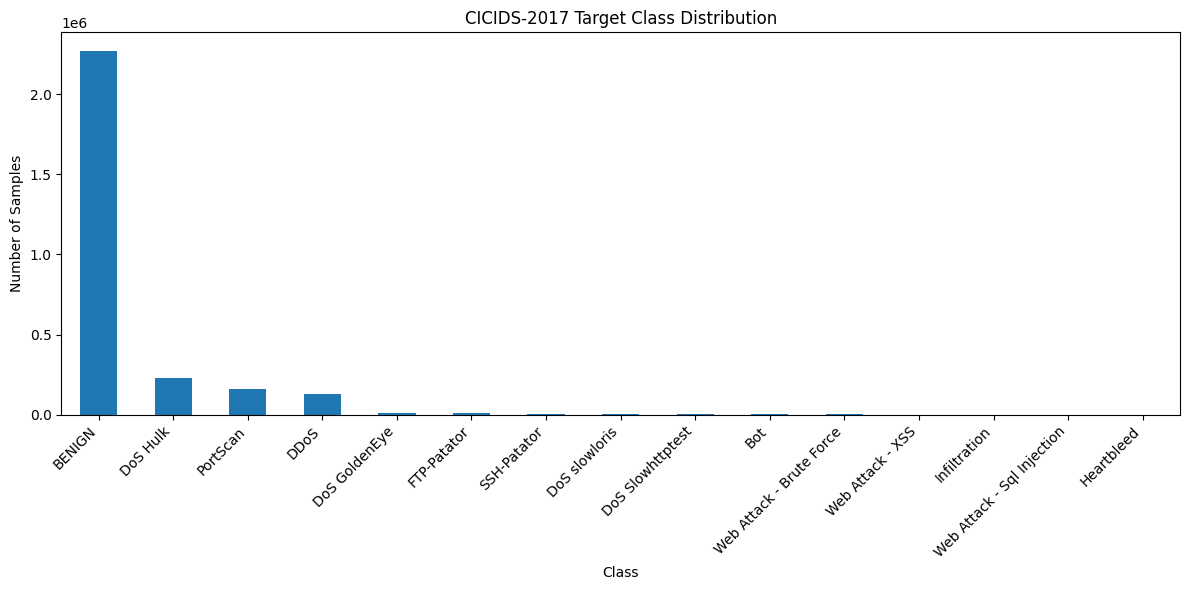

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

class_distribution.plot(kind="bar")

plt.title("CICIDS-2017 Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

### 1.4 Analyze Feature Data Types

The data types of the input features are examined to determine whether the dataset contains numerical, categorical, or non-standard feature representations.

Understanding feature types is necessary before applying scaling, transformation, correlation analysis, and feature selection techniques.

In [13]:
X.dtypes.value_counts()

,count
int64,34
float64,31


### 1.5 Identify Non-Numeric Features

Most CICIDS-2017 flow features are numerical. Any non-numeric features are identified separately because numerical preprocessing techniques cannot be directly applied to them without an appropriate transformation.

In [14]:
non_numeric_columns = X.select_dtypes(exclude=np.number).columns.tolist()

print("Number of non-numeric features:", len(non_numeric_columns))

if non_numeric_columns:
    print("\nNon-numeric features:")
    for column in non_numeric_columns:
        print("-", column)
else:
    print("All input features are numeric.")

Number of non-numeric features: 0
All input features are numeric.


### 1.6 Check for Constant Features

A constant feature has the same value for every observation and therefore provides no discriminatory information to a machine learning model.

Such features can be safely identified as candidates for removal because they do not contribute to distinguishing between traffic classes.

In [15]:
constant_features = [
    column
    for column in X.columns
    if X[column].nunique(dropna=False) <= 1
]

print("Number of constant features:", len(constant_features))

if constant_features:
    print("\nConstant features:")
    for column in constant_features:
        print("-", column)
else:

    print("No constant features found.")

Number of constant features: 0
No constant features found.


### 1.7 Remove Constant Features

Features identified as constant are removed from the feature matrix because they contain no variation across observations and therefore cannot contribute to classification.

The original dataset remains unchanged; feature engineering is performed on a separate feature matrix.

In [16]:
X = X.drop(columns=constant_features)

print("Feature matrix shape after constant-feature removal:", X.shape)

Feature matrix shape after constant-feature removal: (2830743, 65)


### 1.8 Analyze Feature Distributions

The distributions of the input features are examined to understand their scale, spread, and degree of skewness.

Network-flow features can have substantially different numerical ranges and may exhibit highly skewed distributions because network traffic characteristics vary considerably between normal and attack flows.

Descriptive statistics and skewness are therefore analyzed before selecting appropriate feature transformation and scaling strategies.

Because the cleaned dataset contains millions of observations, visualization is performed on a reproducible sample rather than the complete dataset. This reduces computational and memory overhead while still providing a representative view of the feature distributions.

In [17]:
# Create a reproducible sample for distribution analysis
SAMPLE_SIZE = min(100000, len(X))

X_sample = X.sample(
    n=SAMPLE_SIZE,
    random_state=42
)

print("Distribution analysis sample size:", len(X_sample))

Distribution analysis sample size: 100000


#### 1.8.1 Descriptive Statistics

Descriptive statistics are calculated for the input features to examine their central tendency, spread, and range.

The analysis includes the mean, standard deviation, minimum, maximum, and selected percentiles. These statistics help identify features with substantially different scales and unusual value ranges.

In [18]:
distribution_summary = X.describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]

distribution_summary

,mean,std,min,25%,50%,75%,max
Destination Port,8.071483e+03,1.828363e+04,0.0,53.0,80.0,443.0,65535.0
Flow Duration,1.478567e+07,3.365374e+07,0.0,155.0,31317.0,3204828.5,119999998.0
Total Fwd Packets,9.361160e+00,7.496728e+02,1.0,2.0,2.0,5.0,219759.0
Total Backward Packets,1.039377e+01,9.973883e+02,0.0,1.0,2.0,4.0,291922.0
Total Length of Fwd Packets,5.493024e+02,9.993589e+03,0.0,12.0,62.0,187.0,12900000.0
...,...,...,...,...,...,...,...
Active Min,5.829582e+04,5.770923e+05,0.0,0.0,0.0,0.0,110000000.0
Idle Mean,8.316037e+06,2.363008e+07,0.0,0.0,0.0,0.0,120000000.0
Idle Std,5.038439e+05,4.602984e+06,0.0,0.0,0.0,0.0,76900000.0
Idle Max,8.695752e+06,2.436689e+07,0.0,0.0,0.0,0.0,120000000.0


#### 1.8.2 Analyze Feature Skewness

Feature skewness is examined to identify asymmetric distributions.

Highly skewed features are common in network-traffic datasets because some flow characteristics can contain many small values together with a smaller number of very large observations.

The skewness values are used to guide later decisions regarding feature transformation. No features are removed solely because they are skewed.

In [19]:
feature_skewness = X_sample.skew().sort_values(
    key=lambda values: values.abs(),
    ascending=False
)

skewness_summary = pd.DataFrame({
    "Skewness": feature_skewness,
    "Absolute Skewness": feature_skewness.abs()
})

skewness_summary.head(15)

,Skewness,Absolute Skewness
act_data_pkt_fwd,232.029029,232.029029
Total Fwd Packets,231.645747,231.645747
Fwd Header Length,231.463182,231.463182
Total Backward Packets,230.097692,230.097692
Bwd Header Length,229.857235,229.857235
Total Length of Bwd Packets,229.688037,229.688037
Subflow Bwd Bytes,229.644782,229.644782
Subflow Fwd Bytes,132.709733,132.709733
Total Length of Fwd Packets,132.709733,132.709733
CWE Flag Count,95.331956,95.331956


#### 1.8.3 Visualize Representative Feature Distributions

Representative feature distributions are visualized using the reproducible sample.

The features with the highest absolute skewness are selected for visualization because they provide useful examples of the non-uniform distributions present in the network-flow feature space.

The visualizations are used for analysis only; no transformation or feature removal is performed at this stage.

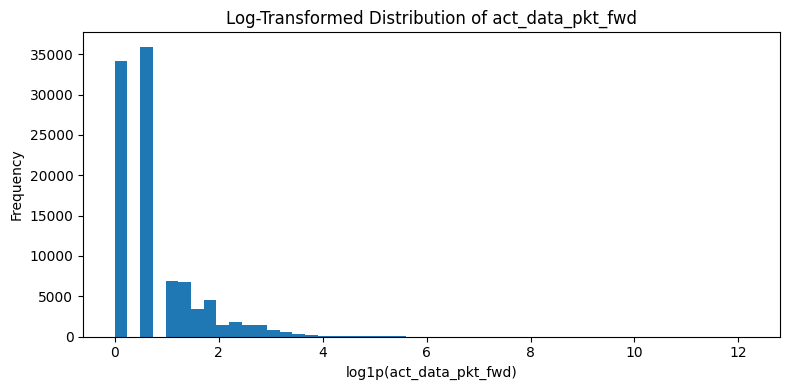

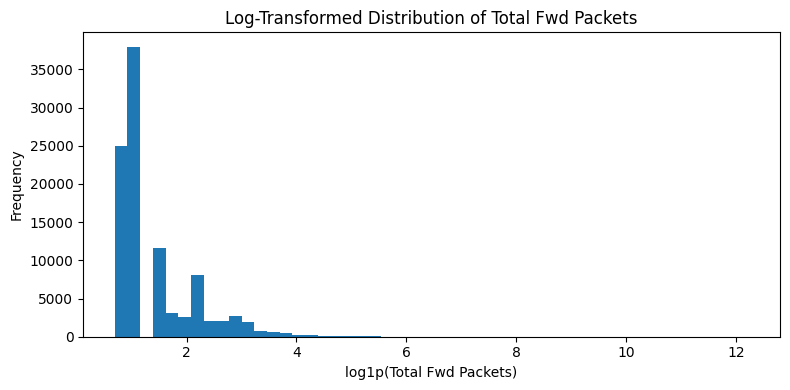

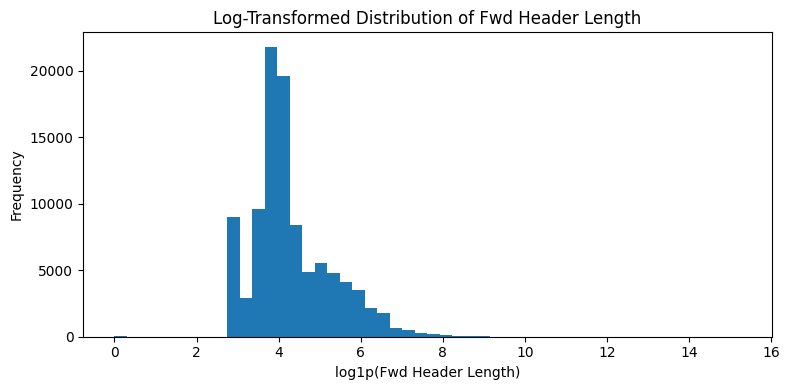

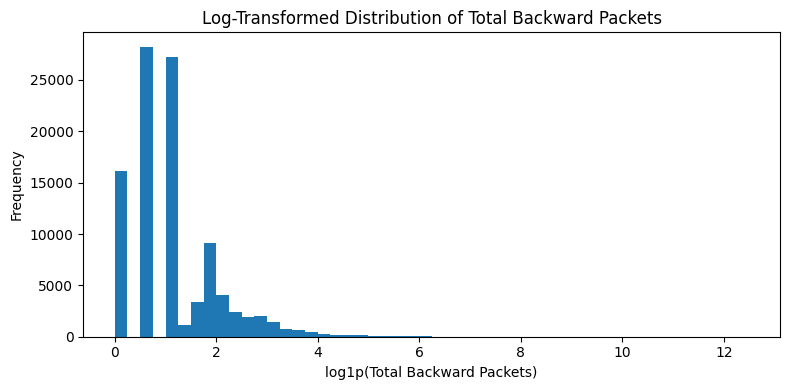

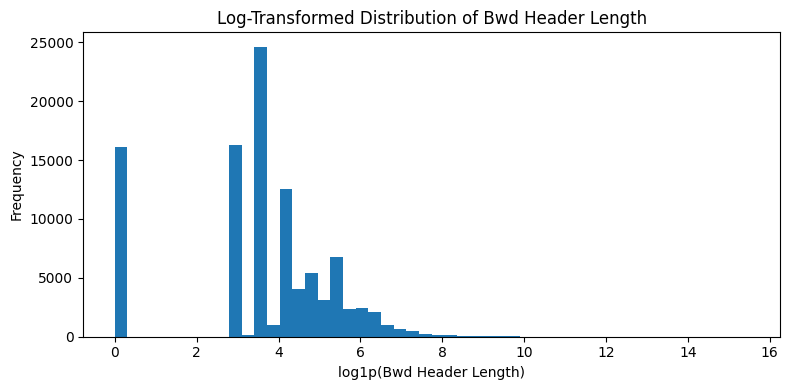

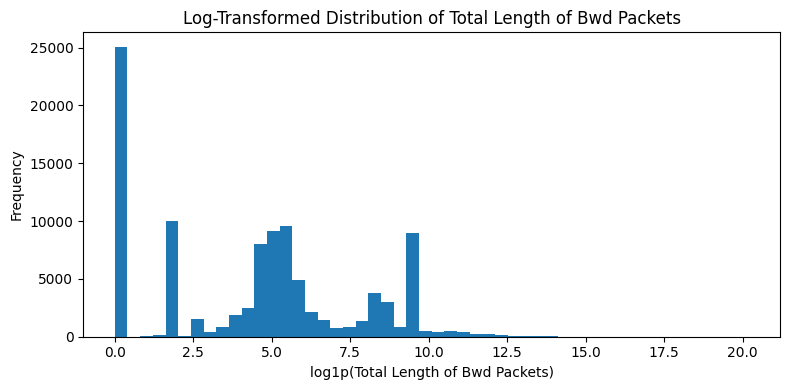

In [20]:
# Select the 6 most skewed features for visualization
top_features = skewness_summary.head(6).index

# Visualize highly skewed features using log1p transformation
# This transformation is used only for visualization and does not modify X.

for feature in top_features:
    plt.figure(figsize=(8, 4))

    log_values = np.log1p(X_sample[feature])

    plt.hist(log_values, bins=50)

    plt.title(f"Log-Transformed Distribution of {feature}")
    plt.xlabel(f"log1p({feature})")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

### 1.8.4 Distribution Analysis Findings

The log-transformed distributions were examined for the most highly skewed numerical features identified in the previous analysis.

The `log1p` transformation compresses large values and reduces the influence of extreme observations. However, several features remain right-skewed after transformation, while some features retain discrete or multimodal distribution patterns.

The analysis indicates that:

- `act_data_pkt_fwd`, `Total Fwd Packets`, and `Total Backward Packets` remain strongly concentrated toward lower values.
- `Fwd Header Length` and `Bwd Header Length` show more compact distributions after transformation, although some right skew remains.
- `Total Length of Bwd Packets` retains a multimodal distribution even after transformation.
- Log transformation therefore improves the scale of highly skewed features but does not completely normalize their distributions.

No features are removed solely because of skewness at this stage. The original feature values are retained, and transformation requirements will be considered later according to the requirements of the selected machine learning models.

### 1.9 Correlation Analysis

Correlation analysis is performed to identify highly related input features that may contain overlapping information.

Highly correlated features can indicate redundancy within the feature space. Identifying such relationships is useful for reducing unnecessary dimensionality and understanding the structure of the network-traffic features.

The correlation analysis is performed on the previously created 100,000-record sample to reduce computational and memory requirements.

At this stage, correlation is used for analysis only. Features will not be removed solely because they are highly correlated; any feature-removal decision will be based on the observed relationships and the requirements of the subsequent machine learning models.

### 1.9.1 Compute Feature Correlation Matrix

The Pearson correlation coefficient is calculated between the numerical input features.

The correlation coefficient ranges from -1 to +1:

- Values close to +1 indicate a strong positive relationship.
- Values close to -1 indicate a strong negative relationship.
- Values close to 0 indicate a weak linear relationship.

The absolute correlation value is considered when identifying highly correlated feature pairs.

In [21]:
# Compute the correlation matrix using the analysis sample

correlation_matrix = X_sample.corr()

print("Correlation matrix shape:", correlation_matrix.shape)

Correlation matrix shape: (65, 65)


### 1.9.2 Identify Highly Correlated Feature Pairs

To focus the analysis on potentially redundant relationships, feature pairs with an absolute Pearson correlation of 0.90 or greater are identified.

The upper triangle of the correlation matrix is used so that each feature pair is reported only once.

In [22]:
# Identify highly correlated feature pairs

CORRELATION_THRESHOLD = 0.90

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_correlation_pairs["Absolute Correlation"] = (
    high_correlation_pairs["Correlation"].abs()
)

high_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["Absolute Correlation"] >= CORRELATION_THRESHOLD
    ]
    .sort_values("Absolute Correlation", ascending=False)
    .reset_index(drop=True)
)

print(
    f"Number of highly correlated feature pairs "
    f"(absolute correlation >= {CORRELATION_THRESHOLD}):",
    len(high_correlation_pairs)
)

high_correlation_pairs

Number of highly correlated feature pairs (absolute correlation >= 0.9): 74


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
1,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
2,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
3,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
4,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
...,...,...,...,...
69,Fwd IAT Std,Idle Max,0.911451,0.911451
70,Flow IAT Std,Idle Min,0.909377,0.909377
71,Max Packet Length,Avg Bwd Segment Size,0.904325,0.904325
72,Bwd Packet Length Mean,Max Packet Length,0.904325,0.904325


### 1.9.3 Visualize Strongest Feature Relationships

The strongest correlated feature pairs are visualized to make the redundancy patterns easier to interpret.

Only the highest-correlated relationships are displayed rather than plotting the complete 65 × 65 correlation matrix.

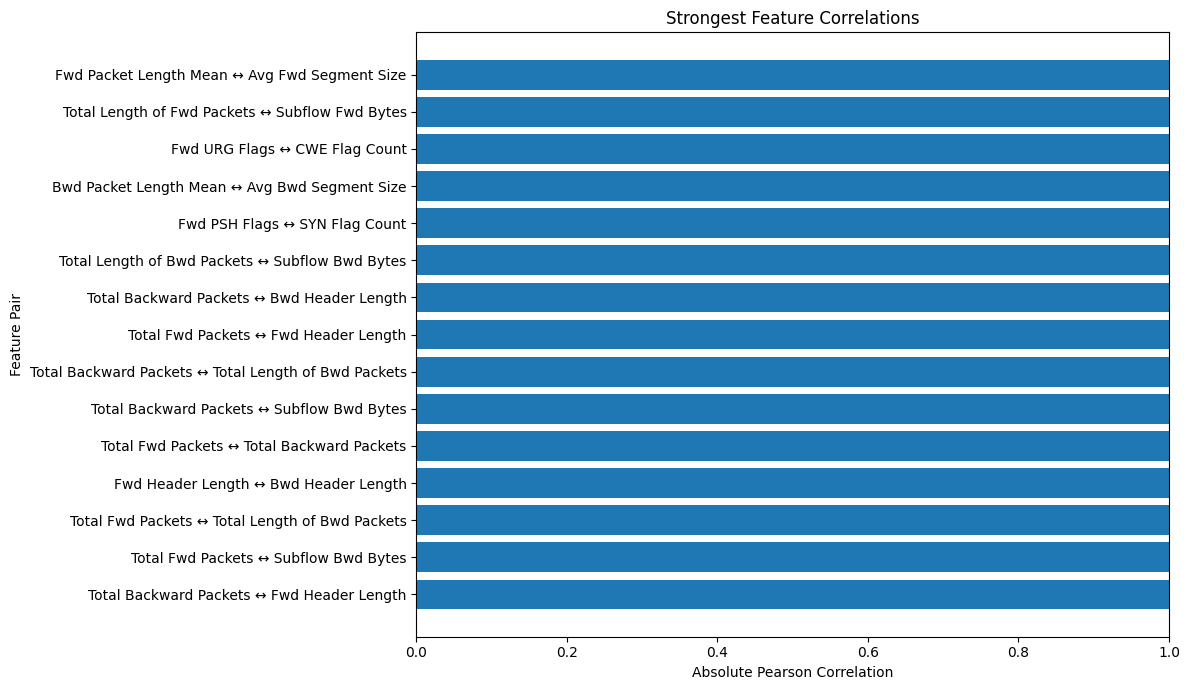

In [23]:
# Visualize the strongest correlated feature pairs

TOP_N_CORRELATIONS = 15

top_correlations = high_correlation_pairs.head(TOP_N_CORRELATIONS).copy()

top_correlations["Feature Pair"] = (
    top_correlations["Feature 1"]
    + " ↔ "
    + top_correlations["Feature 2"]
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_correlations["Feature Pair"][::-1],
    top_correlations["Absolute Correlation"][::-1]
)

plt.xlabel("Absolute Pearson Correlation")
plt.ylabel("Feature Pair")
plt.title("Strongest Feature Correlations")

plt.xlim(0, 1.0)
plt.tight_layout()
plt.show()

### 1.9.4 Investigate Highly Correlated Features

The correlation analysis identified several strongly related feature pairs, including multiple pairs with an absolute correlation of 1.00.

Perfect or near-perfect correlation suggests that some features may contain identical or substantially overlapping information. Such relationships can increase feature redundancy and may unnecessarily increase the dimensionality of the feature space.

Before removing any features, the highly correlated pairs are examined in greater detail to determine whether the relationship is caused by:

- identical feature values,
- deterministic relationships between derived features,
- or simply strong statistical association.

No feature is removed solely on the basis of correlation at this stage.

In [24]:
# Display the strongest correlated feature pairs

VERY_HIGH_CORRELATION = 0.95

very_high_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["Absolute Correlation"] >= VERY_HIGH_CORRELATION
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"Number of feature pairs with absolute correlation >= "
    f"{VERY_HIGH_CORRELATION}:",
    len(very_high_correlation_pairs)
)

very_high_correlation_pairs

Number of feature pairs with absolute correlation >= 0.95: 45


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
1,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
2,Fwd URG Flags,CWE Flag Count,1.000000,1.000000
3,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
4,Fwd PSH Flags,SYN Flag Count,1.000000,1.000000
5,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
6,Total Backward Packets,Bwd Header Length,0.999920,0.999920
7,Total Fwd Packets,Fwd Header Length,0.999887,0.999887
8,Total Backward Packets,Total Length of Bwd Packets,0.999872,0.999872
9,Total Backward Packets,Subflow Bwd Bytes,0.999870,0.999870


### 1.9.5 Check for Identical Feature Columns

Features with a perfect correlation of 1.00 are examined to determine whether they contain identical values for every observation.

Identical columns provide duplicate information and are strong candidates for removal. This check is performed on the complete feature matrix rather than relying only on the correlation coefficient calculated from the analysis sample.

In [25]:
# Identify perfectly correlated feature pairs

perfect_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["Absolute Correlation"] == 1.0
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Number of perfectly correlated feature pairs:",
    len(perfect_correlation_pairs)
)

perfect_correlation_pairs

Number of perfectly correlated feature pairs: 5


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Fwd Packet Length Mean,Avg Fwd Segment Size,1.0,1.0
1,Total Length of Fwd Packets,Subflow Fwd Bytes,1.0,1.0
2,Fwd URG Flags,CWE Flag Count,1.0,1.0
3,Bwd Packet Length Mean,Avg Bwd Segment Size,1.0,1.0
4,Fwd PSH Flags,SYN Flag Count,1.0,1.0


In [26]:
# Verify whether perfectly correlated feature pairs
# contain identical values across the complete dataset.

identical_feature_pairs = []

for _, row in perfect_correlation_pairs.iterrows():
    feature_1 = row["Feature 1"]
    feature_2 = row["Feature 2"]

    are_identical = X[feature_1].equals(X[feature_2])

    identical_feature_pairs.append({
        "Feature 1": feature_1,
        "Feature 2": feature_2,
        "Identical": are_identical
    })

identical_feature_pairs = pd.DataFrame(identical_feature_pairs)

identical_feature_pairs

,Feature 1,Feature 2,Identical
0,Fwd Packet Length Mean,Avg Fwd Segment Size,False
1,Total Length of Fwd Packets,Subflow Fwd Bytes,False
2,Fwd URG Flags,CWE Flag Count,True
3,Bwd Packet Length Mean,Avg Bwd Segment Size,False
4,Fwd PSH Flags,SYN Flag Count,True


### 1.9.6 Validate Perfect Correlations on the Complete Dataset

The perfectly correlated feature pairs identified from the analysis sample are validated against the complete feature matrix.

A pair is considered an exact duplicate only when the two columns contain identical values for every record.

Only exact duplicate features will be considered for removal. Features that are highly correlated but not identical will be retained for further analysis because correlation alone does not establish that one feature can be safely removed.

In [27]:
# Display only the feature pairs that are exact duplicates

duplicate_feature_pairs = identical_feature_pairs[
    identical_feature_pairs["Identical"]
].copy()

print(
    "Number of exact duplicate feature pairs:",
    len(duplicate_feature_pairs)
)

duplicate_feature_pairs

Number of exact duplicate feature pairs: 2


,Feature 1,Feature 2,Identical
2,Fwd URG Flags,CWE Flag Count,True
4,Fwd PSH Flags,SYN Flag Count,True


### 1.9.7 Investigate Exact Duplicate Features

The complete-dataset validation identified two pairs of features with identical values across all observations.

Before removing these features, their value distributions and feature meanings are examined to confirm that the duplication is genuine and that removing one member of each pair will not discard unique information.

The investigation focuses on:
- Number of unique values
- Value frequencies
- Minimum and maximum values
- Comparison of the two columns

In [28]:
# Examine the exact duplicate feature pairs in detail

for _, row in duplicate_feature_pairs.iterrows():

    feature_1 = row["Feature 1"]
    feature_2 = row["Feature 2"]

    print("=" * 80)
    print(f"Feature 1: {feature_1}")
    print(f"Feature 2: {feature_2}")

    print("\nNumber of unique values:")
    print(f"{feature_1}: {X[feature_1].nunique()}")
    print(f"{feature_2}: {X[feature_2].nunique()}")

    print("\nValue counts:")
    print(X[feature_1].value_counts().sort_index())

    print("\nBasic statistics:")
    print(
        X[[feature_1, feature_2]]
        .describe()
        .loc[["min", "max", "mean", "std"]]
    )

Feature 1: Fwd URG Flags
Feature 2: CWE Flag Count

Number of unique values:
Fwd URG Flags: 2
CWE Flag Count: 2

Value counts:
Fwd URG Flags
0    2830428
1        315
Name: count, dtype: int64

Basic statistics:
      Fwd URG Flags  CWE Flag Count
min        0.000000        0.000000
max        1.000000        1.000000
mean       0.000111        0.000111
std        0.010548        0.010548
Feature 1: Fwd PSH Flags
Feature 2: SYN Flag Count

Number of unique values:
Fwd PSH Flags: 2
SYN Flag Count: 2

Value counts:
Fwd PSH Flags
0    2699265
1     131478
Name: count, dtype: int64

Basic statistics:
      Fwd PSH Flags  SYN Flag Count
min        0.000000        0.000000
max        1.000000        1.000000
mean       0.046446        0.046446
std        0.210450        0.210450


### 1.9.8 Remove Confirmed Duplicate Features

The investigation confirms that the identified feature pairs contain identical information across the complete dataset.

To reduce redundant representations without discarding unique information, one feature from each exact duplicate pair is removed.

The retained features are selected based on preserving the more descriptive feature representation, while the redundant duplicates are excluded from the feature matrix.

In [29]:
# Features selected for removal after complete-dataset validation

features_to_remove = [
    "CWE Flag Count",
    "SYN Flag Count"
]

print("Features selected for removal:")
for feature in features_to_remove:
    print("-", feature)

print("\nFeature matrix shape before removal:", X.shape)

X = X.drop(columns=features_to_remove)

print("Feature matrix shape after removal:", X.shape)

Features selected for removal:
- CWE Flag Count
- SYN Flag Count

Feature matrix shape before removal: (2830743, 65)
Feature matrix shape after removal: (2830743, 63)


### 1.9.9 Verify Feature Matrix After Redundancy Removal

After removing the confirmed duplicate features, the resulting feature matrix is inspected to verify its dimensions and confirm that the target and previously removed features are no longer part of the input feature set.

This provides a final checkpoint before proceeding with further feature analysis.

In [30]:
# Verify the feature matrix after duplicate-feature removal

print("Number of records:", X.shape[0])
print("Number of input features:", X.shape[1])

print("\nRemaining feature columns:")
for i, column in enumerate(X.columns, start=1):
    print(f"{i}. {column}")

print("\nTarget variable:", TARGET_COLUMN)

print("\nRemoved features still present in X:")
print([
    feature for feature in features_to_remove
    if feature in X.columns
])

Number of records: 2830743
Number of input features: 63

Remaining feature columns:
1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Fwd URG Flags
33. Fwd Header Length
34. Bwd Header Length
35. Fwd Packets/s
36. Bwd Packets/s
37. Min Packet Length
38. Max Packet Length
39. Packet Length Mean
40. Packet Length Std
41. Packet Length Variance
42. FIN Flag Count
43. RST Flag Count
44. PSH Flag Count
45.

### 1.10 Identify Near-Constant Features

After removing constant features, the remaining input features are examined for near-constant behavior.

A near-constant feature is a feature in which one value occurs for an overwhelmingly large proportion of observations, leaving very little variation across the dataset.

Near-constant features are identified as candidates for further investigation rather than being automatically removed. This is important for intrusion detection because rare-valued features, particularly network flag features, may still provide useful information for detecting minority attack classes.

In [31]:
# Identify near-constant features based on dominant-value frequency

NEAR_CONSTANT_THRESHOLD = 0.999

near_constant_features = []

for column in X.columns:

    value_counts = X[column].value_counts(dropna=False)

    dominant_value = value_counts.index[0]
    dominant_count = value_counts.iloc[0]
    dominant_ratio = dominant_count / len(X)

    near_constant_features.append({
        "Feature": column,
        "Dominant Value": dominant_value,
        "Dominant Count": dominant_count,
        "Dominant Ratio": dominant_ratio,
        "Unique Values": X[column].nunique(dropna=False)
    })

near_constant_features = pd.DataFrame(near_constant_features)

near_constant_features = (
    near_constant_features[
        near_constant_features["Dominant Ratio"] >= NEAR_CONSTANT_THRESHOLD
    ]
    .sort_values("Dominant Ratio", ascending=False)
    .reset_index(drop=True)
)

print(
    f"Near-constant threshold: "
    f"{NEAR_CONSTANT_THRESHOLD:.3%}"
)

print(
    "Number of near-constant features:",
    len(near_constant_features)
)

near_constant_features

Near-constant threshold: 99.900%
Number of near-constant features: 3


,Feature,Dominant Value,Dominant Count,Dominant Ratio,Unique Values
0,Fwd URG Flags,0.0,2830428,0.999889,2
1,RST Flag Count,0.0,2830057,0.999758,2
2,ECE Flag Count,0.0,2830054,0.999757,2


### 1.10.1 Validate Near-Constant Features Against Target

The near-constant features are further examined against the target classes before any removal decision is made.

The purpose is to determine whether the rare values of these features are associated with particular attack classes. A feature may have very low overall variation while still providing useful information for intrusion detection.

Therefore, near-constant features are retained unless the analysis provides sufficient evidence that they contribute little useful information.

In [32]:
# Examine the distribution of rare values across target classes

near_constant_candidates = near_constant_features["Feature"].tolist()

for feature in near_constant_candidates:

    print("=" * 80)
    print(f"Feature: {feature}")

    # Cross-tabulation of feature values and target classes
    feature_target_distribution = pd.crosstab(
        df[feature],
        df[LABEL_COLUMN],
        normalize="columns"
    ) * 100

    print("\nPercentage distribution of feature values within each target class:")
    display(feature_target_distribution.round(4))

    # Overall value counts
    print("\nOverall value counts:")
    print(df[feature].value_counts())

Feature: Fwd URG Flags

Percentage distribution of feature values within each target class:


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Fwd URG Flags,,,,,,,,,,,,,,,
0,99.9861,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1,0.0139,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Overall value counts:
Fwd URG Flags
0    2830428
1        315
Name: count, dtype: int64
Feature: RST Flag Count

Percentage distribution of feature values within each target class:


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
RST Flag Count,,,,,,,,,,,,,,,
0,99.9698,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1,0.0302,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Overall value counts:
RST Flag Count
0    2830057
1        686
Name: count, dtype: int64
Feature: ECE Flag Count

Percentage distribution of feature values within each target class:


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
ECE Flag Count,,,,,,,,,,,,,,,
0,99.9697,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1,0.0303,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Overall value counts:
ECE Flag Count
0    2830054
1        689
Name: count, dtype: int64


### 1.10.2 Quantify Near-Constant Feature Association

The near-constant features are evaluated quantitatively to determine whether their rare non-zero values are associated with specific target classes.

Although these features have extremely low variance, the previous analysis showed that their non-zero values occur exclusively within the BENIGN class. Therefore, they are retained temporarily rather than removed solely on the basis of their near-constant distributions.

Their contribution will be reconsidered during subsequent feature-selection and model-evaluation stages.

In [33]:
# Quantify the target association of near-constant features

for feature in near_constant_candidates:

    print("=" * 80)
    print(f"Feature: {feature}")

    # Number of records for each feature value
    value_counts = df[feature].value_counts()

    print("\nFeature value counts:")
    print(value_counts)

    # Target distribution when feature == 1
    print("\nTarget distribution when feature == 1:")

    positive_target_distribution = (
        df.loc[df[feature] == 1, LABEL_COLUMN]
        .value_counts()
        .to_frame("Count")
    )

    positive_target_distribution["Percentage"] = (
        positive_target_distribution["Count"]
        / positive_target_distribution["Count"].sum()
        * 100
    )

    display(positive_target_distribution)

    # Number of classes represented by the rare value
    number_of_classes = df.loc[
        df[feature] == 1, LABEL_COLUMN
    ].nunique()

    print(
        f"Number of target classes containing value 1: "
        f"{number_of_classes}"
    )

Feature: Fwd URG Flags

Feature value counts:
Fwd URG Flags
0    2830428
1        315
Name: count, dtype: int64

Target distribution when feature == 1:


,Count,Percentage
Label,,
BENIGN,315,100.0


Number of target classes containing value 1: 1
Feature: RST Flag Count

Feature value counts:
RST Flag Count
0    2830057
1        686
Name: count, dtype: int64

Target distribution when feature == 1:


,Count,Percentage
Label,,
BENIGN,686,100.0


Number of target classes containing value 1: 1
Feature: ECE Flag Count

Feature value counts:
ECE Flag Count
0    2830054
1        689
Name: count, dtype: int64

Target distribution when feature == 1:


,Count,Percentage
Label,,
BENIGN,689,100.0


Number of target classes containing value 1: 1


### 1.10.3 Near-Constant Feature Decision

The near-constant feature analysis identified three candidate features:

- Fwd URG Flags
- RST Flag Count
- ECE Flag Count

All three features have extremely low occurrence of the value `1`. However, target-wise analysis shows that their non-zero values occur exclusively within the BENIGN class.

Therefore, these features are not removed at this stage solely based on their near-constant distribution. They are retained temporarily because they exhibit a measurable association with the target.

Final feature-selection decisions will be made later using additional statistical and model-based analysis.

### 1.11 Identify Highly Skewed Features

The remaining input features are examined for distributional skewness. Highly skewed features can contain extreme values and long-tailed distributions, which may affect distance-based, linear, and gradient-based machine learning algorithms.

Skewness is therefore used to identify candidate features for transformation. No feature is removed solely because it is highly skewed.

For non-negative features with strong right skew, a log1p transformation is considered as a possible preprocessing step.

In [34]:
# Calculate skewness for all remaining numerical features

feature_skewness = X.skew().sort_values(
    key=lambda values: values.abs(),
    ascending=False
)

skewness_summary = pd.DataFrame({
    "Skewness": feature_skewness,
    "Absolute Skewness": feature_skewness.abs()
})

print("Number of features analyzed:", len(skewness_summary))

display(skewness_summary)

Number of features analyzed: 63


,Skewness,Absolute Skewness
Total Length of Fwd Packets,805.570539,805.570539
Subflow Fwd Bytes,803.598592,803.598592
act_data_pkt_fwd,284.595228,284.595228
Total Backward Packets,244.679507,244.679507
Total Fwd Packets,244.380553,244.380553
...,...,...
Flow Duration,2.155356,2.155356
Destination Port,2.072052,2.072052
PSH Flag Count,0.882925,0.882925
ACK Flag Count,0.792321,0.792321


### 1.11.1 Identify Strongly Skewed Features

In [35]:
# Identify features with strong right/left skew

SKEWNESS_THRESHOLD = 1.0

highly_skewed_features = skewness_summary[
    skewness_summary["Absolute Skewness"] >= SKEWNESS_THRESHOLD
].copy()

print(
    f"Number of highly skewed features "
    f"(absolute skewness >= {SKEWNESS_THRESHOLD}):",
    len(highly_skewed_features)
)

display(highly_skewed_features)

Number of highly skewed features (absolute skewness >= 1.0): 60


,Skewness,Absolute Skewness
Total Length of Fwd Packets,805.570539,805.570539
Subflow Fwd Bytes,803.598592,803.598592
act_data_pkt_fwd,284.595228,284.595228
Total Backward Packets,244.679507,244.679507
Total Fwd Packets,244.380553,244.380553
Subflow Bwd Bytes,244.335301,244.335301
Total Length of Bwd Packets,244.330893,244.330893
Fwd Header Length,243.516039,243.516039
Bwd Header Length,243.471741,243.471741
Fwd URG Flags,94.781303,94.781303


### 1.11.2 Check Whether the Skewed Features Are Suitable for log1p

In [36]:
# Check whether highly skewed features contain negative values

skewed_feature_safety = []

for feature in highly_skewed_features.index:

    min_value = X[feature].min()
    max_value = X[feature].max()
    zero_count = (X[feature] == 0).sum()
    negative_count = (X[feature] < 0).sum()

    skewed_feature_safety.append({
        "Feature": feature,
        "Min": min_value,
        "Max": max_value,
        "Zero Count": zero_count,
        "Negative Count": negative_count
    })

skewed_feature_safety = pd.DataFrame(skewed_feature_safety)

display(skewed_feature_safety)

,Feature,Min,Max,Zero Count,Negative Count
0,Total Length of Fwd Packets,0.000000,1.290000e+07,449170,0
1,Subflow Fwd Bytes,0.000000,1.287034e+07,449170,0
2,act_data_pkt_fwd,0.000000,2.135570e+05,962924,0
3,Total Backward Packets,0.000000,2.919220e+05,453519,0
4,Total Fwd Packets,1.000000,2.197590e+05,0,0
5,Subflow Bwd Bytes,0.000000,6.554530e+08,707746,0
6,Total Length of Bwd Packets,0.000000,6.554530e+08,707746,0
7,Fwd Header Length,0.000000,4.644908e+06,1758,0
8,Bwd Header Length,0.000000,5.838440e+06,453651,0
9,Fwd URG Flags,0.000000,1.000000e+00,2830428,0


### 1.11.3 Select Candidates for Log Transformation

Highly skewed features are screened for transformation based on their statistical properties.

Binary or near-binary flag features are excluded because their skewness is primarily caused by the rarity of the non-zero value rather than a continuous long-tailed distribution.

Only non-negative numerical features with more than two unique values are considered as candidates for log transformation.

The transformation is applied to a separate feature matrix so that the original feature representation remains available for comparison.

In [37]:
# Identify non-binary, non-negative, highly skewed features
# suitable as candidates for log1p transformation

LOG_SKEW_THRESHOLD = 1.0

log_transform_candidates = []

for feature in X.columns:

    # Skip features with two or fewer unique values
    if X[feature].nunique() <= 2:
        continue

    # Skip features containing negative values
    if X[feature].min() < 0:
        continue

    # Skip Destination Port because it represents a network port
    if feature == "Destination Port":
        continue

    # Select strongly skewed features
    if abs(X[feature].skew()) >= LOG_SKEW_THRESHOLD:
        log_transform_candidates.append(feature)

print(
    "Number of log-transformation candidates:",
    len(log_transform_candidates)
)

print("\nCandidates:")
for i, feature in enumerate(log_transform_candidates, 1):
    print(f"{i}. {feature}")

Number of log-transformation candidates: 53

Candidates:
1. Flow Duration
2. Total Fwd Packets
3. Total Backward Packets
4. Total Length of Fwd Packets
5. Total Length of Bwd Packets
6. Fwd Packet Length Max
7. Fwd Packet Length Min
8. Fwd Packet Length Mean
9. Fwd Packet Length Std
10. Bwd Packet Length Max
11. Bwd Packet Length Min
12. Bwd Packet Length Mean
13. Bwd Packet Length Std
14. Flow Bytes/s
15. Flow Packets/s
16. Flow IAT Mean
17. Flow IAT Std
18. Flow IAT Max
19. Flow IAT Min
20. Fwd IAT Total
21. Fwd IAT Mean
22. Fwd IAT Std
23. Fwd IAT Max
24. Fwd IAT Min
25. Bwd IAT Total
26. Bwd IAT Mean
27. Bwd IAT Std
28. Bwd IAT Max
29. Bwd IAT Min
30. Fwd Header Length
31. Bwd Header Length
32. Fwd Packets/s
33. Bwd Packets/s
34. Min Packet Length
35. Max Packet Length
36. Packet Length Mean
37. Packet Length Std
38. Packet Length Variance
39. Down/Up Ratio
40. Average Packet Size
41. Avg Fwd Segment Size
42. Avg Bwd Segment Size
43. Subflow Fwd Bytes
44. Subflow Bwd Bytes
45. act_

### 1.11.4 Create a Separate Transformed Matrix

In [38]:
# Create a separate feature matrix for transformation

X_transformed = X.copy()

for feature in log_transform_candidates:
    X_transformed[feature] = np.log1p(X_transformed[feature])

print("Original feature matrix shape:", X.shape)
print("Transformed feature matrix shape:", X_transformed.shape)

Original feature matrix shape: (2830743, 63)
Transformed feature matrix shape: (2830743, 63)


### 1.11.5 Check Whether Transformation Actually Reduced Skewness

In [39]:
# Compare skewness before and after log transformation

transformation_comparison = pd.DataFrame({
    "Original Skewness": X[log_transform_candidates].skew(),
    "Transformed Skewness": X_transformed[log_transform_candidates].skew()
})

transformation_comparison["Original |Skewness|"] = (
    transformation_comparison["Original Skewness"].abs()
)

transformation_comparison["Transformed |Skewness|"] = (
    transformation_comparison["Transformed Skewness"].abs()
)

transformation_comparison["Reduction"] = (
    transformation_comparison["Original |Skewness|"]
    - transformation_comparison["Transformed |Skewness|"]
)

transformation_comparison = transformation_comparison.sort_values(
    "Reduction",
    ascending=False
)

display(transformation_comparison)

,Original Skewness,Transformed Skewness,Original |Skewness|,Transformed |Skewness|,Reduction
Total Length of Fwd Packets,805.570539,-0.082995,805.570539,0.082995,805.487544
Subflow Fwd Bytes,803.598592,-0.082995,803.598592,0.082995,803.515596
act_data_pkt_fwd,284.595228,1.468468,284.595228,1.468468,283.126759
Subflow Bwd Bytes,244.335301,0.145083,244.335301,0.145083,244.190218
Total Length of Bwd Packets,244.330893,0.145083,244.330893,0.145083,244.185810
Total Backward Packets,244.679507,1.385260,244.679507,1.385260,243.294247
Bwd Header Length,243.471741,-0.587743,243.471741,0.587743,242.883998
Total Fwd Packets,244.380553,1.769675,244.380553,1.769675,242.610878
Fwd Header Length,243.516039,1.140782,243.516039,1.140782,242.375257
Flow Bytes/s,46.420148,-0.188912,46.420148,0.188912,46.231236


### 1.11.6 Finalize Transformed Feature Representation

The comparison between the original and log-transformed distributions shows that log1p transformation substantially reduces the extreme positive skewness present in several network-flow features.

For example, the skewness of Total Length of Fwd Packets decreases from approximately 805.57 to 0.08 in absolute terms, while Subflow Fwd Bytes decreases from approximately 803.60 to 0.08.

The transformation is therefore retained for the identified non-binary, non-negative, highly skewed features.

Binary and near-binary flag features are not log-transformed because their skewness is primarily caused by their highly imbalanced binary value distribution.

The transformed feature matrix is retained separately from the original representation for subsequent preprocessing and modeling.

In [40]:
# Final transformed feature matrix for subsequent analysis

X_final = X_transformed.copy()

print("Final feature matrix shape:", X_final.shape)

print("\nNumber of transformed features:",
      len(log_transform_candidates))

print("\nTransformed features:")
for i, feature in enumerate(log_transform_candidates, 1):
    print(f"{i}. {feature}")

Final feature matrix shape: (2830743, 63)

Number of transformed features: 53

Transformed features:
1. Flow Duration
2. Total Fwd Packets
3. Total Backward Packets
4. Total Length of Fwd Packets
5. Total Length of Bwd Packets
6. Fwd Packet Length Max
7. Fwd Packet Length Min
8. Fwd Packet Length Mean
9. Fwd Packet Length Std
10. Bwd Packet Length Max
11. Bwd Packet Length Min
12. Bwd Packet Length Mean
13. Bwd Packet Length Std
14. Flow Bytes/s
15. Flow Packets/s
16. Flow IAT Mean
17. Flow IAT Std
18. Flow IAT Max
19. Flow IAT Min
20. Fwd IAT Total
21. Fwd IAT Mean
22. Fwd IAT Std
23. Fwd IAT Max
24. Fwd IAT Min
25. Bwd IAT Total
26. Bwd IAT Mean
27. Bwd IAT Std
28. Bwd IAT Max
29. Bwd IAT Min
30. Fwd Header Length
31. Bwd Header Length
32. Fwd Packets/s
33. Bwd Packets/s
34. Min Packet Length
35. Max Packet Length
36. Packet Length Mean
37. Packet Length Std
38. Packet Length Variance
39. Down/Up Ratio
40. Average Packet Size
41. Avg Fwd Segment Size
42. Avg Bwd Segment Size
43. Subf

In [41]:
# Validate the final feature matrix

print("NaN values:", X_final.isna().sum().sum())

print("Infinite values:",
      np.isinf(X_final.to_numpy()).sum())

print("Negative values:",
      (X_final < 0).sum().sum())

NaN values: 0
Infinite values: 0
Negative values: 0


### 1.12 Re-analyze Feature Correlations After Transformation

After duplicate feature removal and skewness transformation, the feature relationships are recalculated on the final feature representation.

This step determines whether strong redundancy remains after transformation. Correlation values from the original feature space are not reused because log transformation is nonlinear and may alter Pearson correlation relationships.

Only highly correlated feature groups will be identified at this stage. No additional feature will be removed solely because it is highly correlated; removal decisions will require further examination of the feature relationships and their information content.

In [42]:
# Recalculate correlations on the final transformed feature matrix

CORRELATION_THRESHOLD = 0.90

correlation_matrix_final = X_final.corr()

high_corr_pairs_final = []

columns = correlation_matrix_final.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        corr = correlation_matrix_final.iloc[i, j]

        if abs(corr) >= CORRELATION_THRESHOLD:
            high_corr_pairs_final.append({
                "Feature 1": columns[i],
                "Feature 2": columns[j],
                "Correlation": corr,
                "Absolute Correlation": abs(corr)
            })

high_corr_pairs_final = (
    pd.DataFrame(high_corr_pairs_final)
    .sort_values("Absolute Correlation", ascending=False)
    .reset_index(drop=True)
)

print(
    f"Number of highly correlated feature pairs "
    f"(absolute correlation >= {CORRELATION_THRESHOLD}): "
    f"{len(high_corr_pairs_final)}"
)

high_corr_pairs_final.head(20)

Number of highly correlated feature pairs (absolute correlation >= 0.9): 86


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000,1.000000
1,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000,1.000000
2,Total Length of Fwd Packets,Subflow Fwd Bytes,1.000000,1.000000
3,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000,1.000000
4,Idle Mean,Idle Max,0.999954,0.999954
5,Idle Mean,Idle Min,0.999723,0.999723
6,Packet Length Std,Packet Length Variance,0.999641,0.999641
7,Idle Max,Idle Min,0.999473,0.999473
8,Packet Length Mean,Average Packet Size,0.997960,0.997960
9,Bwd IAT Total,Bwd IAT Max,0.997896,0.997896


In [43]:
perfect_corr_pairs_final = (
    high_corr_pairs_final[
        high_corr_pairs_final["Absolute Correlation"] == 1.0
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Number of perfectly correlated feature pairs after transformation:",
    len(perfect_corr_pairs_final)
)

perfect_corr_pairs_final

Number of perfectly correlated feature pairs after transformation: 1


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Fwd Packet Length Mean,Avg Fwd Segment Size,1.0,1.0


### 1.13 Validate Remaining Perfectly Correlated Features

The transformed feature matrix contains one pair with a perfect Pearson correlation.

Before removing either feature, the pair is validated directly on the complete transformed dataset. A feature pair is considered an exact duplicate only if both columns contain identical values for every record.

This prevents removal of features that are strongly correlated but still contain distinct information.

In [44]:
# Validate the remaining perfectly correlated feature pair

for _, row in perfect_corr_pairs_final.iterrows():

    feature_1 = row["Feature 1"]
    feature_2 = row["Feature 2"]

    identical = X_final[feature_1].equals(X_final[feature_2])

    print("=" * 70)
    print("Feature 1:", feature_1)
    print("Feature 2:", feature_2)
    print("Pearson correlation:", row["Correlation"])
    print("Identical values across complete dataset:", identical)

    print("\nMaximum absolute difference:")
    print(
        np.abs(
            X_final[feature_1].to_numpy() -
            X_final[feature_2].to_numpy()
        ).max()
    )

Feature 1: Fwd Packet Length Mean
Feature 2: Avg Fwd Segment Size
Pearson correlation: 1.0
Identical values across complete dataset: False

Maximum absolute difference:
1.3855583347321954e-13


### 1.14 Final Stage 1 Validation

The final feature matrix is validated after all feature-engineering operations have been completed.

The validation confirms that the resulting representation contains no missing, infinite, or negative values and that the final feature count is consistent with the feature-removal decisions made during the analysis.

The final feature set is therefore ready to be persisted and used as the input to the subsequent preprocessing and modeling stages.

In [45]:
# Final validation of the Stage 1 feature matrix

print("=" * 70)
print("FINAL STAGE 1 FEATURE ENGINEERING VALIDATION")
print("=" * 70)

# Dataset dimensions
print(f"Number of records: {X_final.shape[0]:,}")
print(f"Number of final features: {X_final.shape[1]}")

# Data-quality checks
nan_count = X_final.isna().sum().sum()
infinite_count = np.isinf(X_final.to_numpy()).sum()
negative_count = (X_final < 0).sum().sum()

print(f"\nNaN values: {nan_count:,}")
print(f"Infinite values: {infinite_count:,}")
print(f"Negative values: {negative_count:,}")

# Data types
non_numeric_final = X_final.select_dtypes(
    exclude=np.number
).columns.tolist()

print(f"Non-numeric features: {len(non_numeric_final)}")

# Final validation status
validation_passed = (
    nan_count == 0
    and infinite_count == 0
    and negative_count == 0
    and len(non_numeric_final) == 0
)

print("\n" + "-" * 70)

if validation_passed:
    print("Stage 1 validation: PASSED")
    print("The final feature matrix is numerically valid and ready for persistence.")
else:
    print("Stage 1 validation: FAILED")
    print("Review the reported validation issues before proceeding.")

print("-" * 70)

FINAL STAGE 1 FEATURE ENGINEERING VALIDATION
Number of records: 2,830,743
Number of final features: 63

NaN values: 0
Infinite values: 0
Negative values: 0
Non-numeric features: 0

----------------------------------------------------------------------
Stage 1 validation: PASSED
The final feature matrix is numerically valid and ready for persistence.
----------------------------------------------------------------------


### 1.15 Persist Feature-Engineered Dataset

The validated feature-engineered matrix is persisted for use in subsequent preprocessing and modeling stages.

The final dataset contains the transformed input features together with the target variable. Parquet format is used to preserve the numerical feature representation efficiently while reducing storage requirements and improving loading performance compared with a CSV representation.

A metadata file is also stored to document the final dataset shape, feature columns, target column, and features removed during Stage 1.

In [47]:
# ============================================================
# 1.15 Persist Final Stage 1 Feature-Engineered Dataset
# ============================================================

STAGE1_DATA_PATH = os.path.join(
    PROCESSED_DATA_PATH,
    "CICIDS2017_stage1_feature_engineered.parquet"
)

STAGE1_METADATA_PATH = os.path.join(
    PROCESSED_DATA_PATH,
    "CICIDS2017_stage1_metadata.json"
)

# Reconstruct the complete Stage 1 dataset
# X_final contains the 63 final input features
# df[TARGET_COLUMN] contains the target variable

stage1_df = X_final.copy()
stage1_df[TARGET_COLUMN] = df[TARGET_COLUMN].values

# Persist the Stage 1 dataset to Google Drive
stage1_df.to_parquet(
    STAGE1_DATA_PATH,
    index=False
)

print("=" * 70)
print("STAGE 1 DATASET PERSISTED")
print("=" * 70)

print("Output path:")
print(STAGE1_DATA_PATH)

print("\nDataset shape:")
print(stage1_df.shape)

print("\nNumber of input features:")
print(X_final.shape[1])

print("\nTarget column:")
print(TARGET_COLUMN)

print("\nFile exists:")
print(os.path.exists(STAGE1_DATA_PATH))

print("=" * 70)

STAGE 1 DATASET PERSISTED
Output path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/data/processed/CICIDS2017_stage1_feature_engineered.parquet

Dataset shape:
(2830743, 64)

Number of input features:
63

Target column:
Target

File exists:
True


In [11]:
# ============================================================
# 1.15.1 Persist Stage 1 Metadata — LOW MEMORY VERSION
# ============================================================

import json
import os

STAGE1_METADATA_PATH = os.path.join(
    PROCESSED_DATA_PATH,
    "CICIDS2017_stage1_metadata.json"
)

# Final 63 feature columns from Stage 1
FINAL_FEATURE_COLUMNS = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Max",
    "Fwd Packet Length Min",
    "Fwd Packet Length Mean",
    "Fwd Packet Length Std",
    "Bwd Packet Length Max",
    "Bwd Packet Length Min",
    "Bwd Packet Length Mean",
    "Bwd Packet Length Std",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Bwd IAT Max",
    "Bwd IAT Min",
    "Fwd PSH Flags",
    "Fwd URG Flags",
    "Fwd Header Length",
    "Bwd Header Length",
    "Fwd Packets/s",
    "Bwd Packets/s",
    "Min Packet Length",
    "Max Packet Length",
    "Packet Length Mean",
    "Packet Length Std",
    "Packet Length Variance",
    "FIN Flag Count",
    "RST Flag Count",
    "PSH Flag Count",
    "ACK Flag Count",
    "URG Flag Count",
    "ECE Flag Count",
    "Down/Up Ratio",
    "Average Packet Size",
    "Avg Fwd Segment Size",
    "Avg Bwd Segment Size",
    "Subflow Fwd Bytes",
    "Subflow Bwd Bytes",
    "act_data_pkt_fwd",
    "min_seg_size_forward",
    "Active Mean",
    "Active Std",
    "Active Max",
    "Active Min",
    "Idle Mean",
    "Idle Std",
    "Idle Max",
    "Idle Min"
]

metadata = {
    "stage": "Stage 1 - Feature Engineering",

    "dataset": {
        "name": "CICIDS2017",
        "number_of_records": 2830743,
        "number_of_input_features": 63,
        "target_column": "Target"
    },

    "removed_features": [
        "CWE Flag Count",
        "SYN Flag Count"
    ],

    "feature_transformation": (
        "log1p applied to selected highly skewed "
        "non-binary non-negative features"
    ),

    "validation": {
        "nan_values": 0,
        "infinite_values": 0,
        "negative_values": 0,
        "non_numeric_features": 0
    },

    "feature_columns": FINAL_FEATURE_COLUMNS
}

with open(STAGE1_METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=4)

print("=" * 70)
print("STAGE 1 METADATA PERSISTED")
print("=" * 70)
print("Metadata path:")
print(STAGE1_METADATA_PATH)
print()
print("Number of records:", metadata["dataset"]["number_of_records"])
print("Number of input features:", metadata["dataset"]["number_of_input_features"])
print("Target:", metadata["dataset"]["target_column"])
print("Metadata file exists:", os.path.exists(STAGE1_METADATA_PATH))
print("=" * 70)

STAGE 1 METADATA PERSISTED
Metadata path:
/content/drive/MyDrive/AI-Network-Intrusion-Detection-System/data/processed/CICIDS2017_stage1_metadata.json

Number of records: 2830743
Number of input features: 63
Target: Target
Metadata file exists: True
